# PtyREX → Pelz probe & positions

Takes a PtyREX reconstruction (`.hdf`) and writes the `.h5` file that
`general_interface_ptychotomo_Te.py` (End2EndPtychoTomo) reads from its `results/` folder:

| key | shape | meaning |
|---|---|---|
| `probe` | `(1, n_modes, M, M)` complex64 | real-space probe, centred in the window |
| `best_positions` | `(1, 2, K)` float32 | probe positions in Å from the field centre; row 0 = x, row 1 = y |

There is one reconstruction per file, so in the Pelz notebook every `select_inds` entry must be `0`.

**Edit the settings cell, then run all cells.**

In [2]:
# ---------------- Settings: edit these ----------------
PTYREX_FILE   = "/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_112119/pty_out/initial_recon/ptycho_0_0_20260605-120024.hdf"   # your PtyREX output
TILT          = 1           # tilt number of this dataset; must match the zarr name (<TILT>.zip)
OUTPUT_FOLDER = "/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_112119/pty_out/initial_recon"   # the Pelz notebook's probe_position_path

WINDOW   = None   # probe window in pixels. None = keep PtyREX size (450).
                  # Must equal the detector size of your zarr patterns (e.g. 150 if you binned 450 by 3).
N_MODES  = None   # keep only the first N probe modes (None = all). Every tilt must end up with the same number.
USE_REFINED_POSITIONS = True   # False = nominal scan grid instead of PtyREX's refined positions

ZARR_FILE = None  # optional: path to the matching <TILT>.zip, to check detector size, pixel size and scan count

In [3]:
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt

OUTPUT_FILE = os.path.join(OUTPUT_FOLDER, f"{TILT}.h5")
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

## 1. Read the PtyREX file

What PtyREX stores (checked on a 3.4.1rc output):
- `output_1/probe` has shape `(modes, slices, 1, 1, 3, N, N)`. **Only slice 0 is the probe.** Slices 1, 2, … hold the wave
  inside the sample at the last scan position processed, so they are not used. On the 5th axis, copy 0 is the final probe.
- `output_1/scan_positions` has shape `(1, 2, K)`: pixel coordinates of the **window centre** in the object array,
  row 0 = y (row), row 1 = x (column).
- `common_1/dx` is the real-space pixel size in metres.

In [4]:
with h5py.File(PTYREX_FILE, "r") as f:
    out = f["entry_1/process_1/output_1"]
    probe_all   = out["probe"][()]
    object_size = out["object"].shape[-2:]
    pos_refined = out["scan_positions"][()][0].astype(np.float64)
    pos_nominal = f["entry_1/experiment_1/scan/positions"][()][0].astype(np.float64)
    dx_A        = float(np.ravel(f["entry_1/process_1/common_1/dx"][()])[0]) * 1e10      # m -> Angstrom
    energy_eV   = float(np.ravel(f["entry_1/experiment_1/source/energy"][()])[0])
    rotation    = float(f["entry_1/experiment_1/scan/rotation"][()])

print("probe array      ", probe_all.shape, probe_all.dtype)
print("object size      ", object_size)
print("scan positions   ", pos_refined.shape, "(K =", pos_refined.shape[1], ")")
print(f"pixel size dx     {dx_A:.5f} A")
print(f"energy            {energy_eV:.0f} eV")
print(f"scan rotation     {rotation} deg (already included in the positions)")

probe array       (5, 5, 1, 1, 3, 240, 240) complex64
object size       (3594, 3583)
scan positions    (2, 64770) (K = 64770 )
pixel size dx     0.12678 A
energy            300000 eV
scan rotation     -85.5 deg (already included in the positions)


## 2. Probe: take slice 0, choose modes, crop the window

probe modes        5
mode power (%)     [19.7 16.7 20.2 23.2 20.2]
window            240 px of 240 (30.4 A)


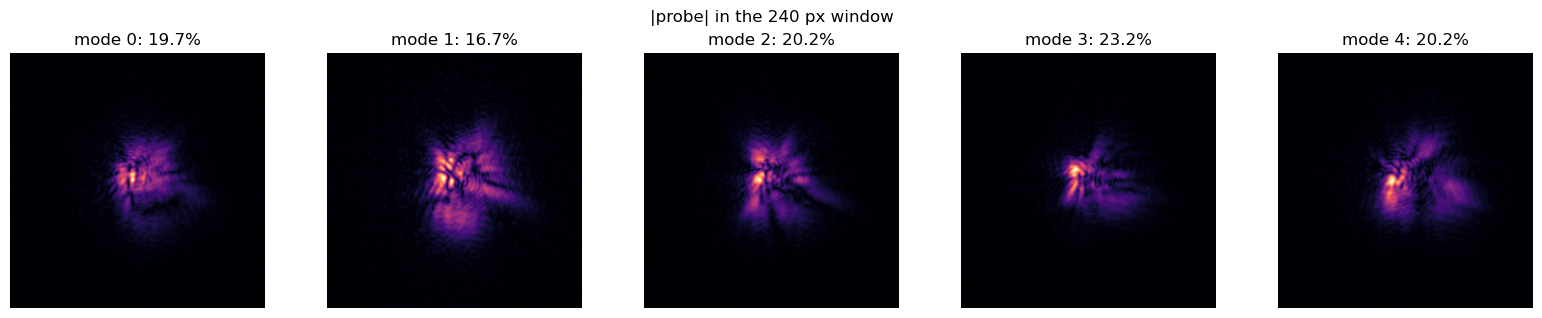

In [5]:
probe = probe_all[:, 0, 0, 0, 0]          # (modes, N, N): entrance-plane probe, final copy
if N_MODES is not None:
    probe = probe[:N_MODES]

N = probe.shape[-1]
M = N if WINDOW is None else WINDOW
start = N // 2 - M // 2                      # keep the probe centred at M/2
probe_out = probe[:, start:start + M, start:start + M].astype(np.complex64)

power = (np.abs(probe) ** 2).sum((1, 2))
print("probe modes       ", probe_out.shape[0])
print("mode power (%)    ", np.round(100 * power / power.sum(), 1))
print(f"window            {M} px of {N} ({M * dx_A:.1f} A)")

fig, ax = plt.subplots(1, probe_out.shape[0], figsize=(3.2 * probe_out.shape[0], 3.2))
ax = np.atleast_1d(ax)
for m in range(probe_out.shape[0]):
    ax[m].imshow(np.abs(probe_out[m]), cmap="magma")
    ax[m].set_title(f"mode {m}: {100 * power[m] / power.sum():.1f}%")
    ax[m].axis("off")
plt.suptitle(f"|probe| in the {M} px window")
plt.tight_layout(); plt.show()

## 3. Positions: pixels → Å, swap to (x, y)

The Pelz notebook divides by dx, adds `scan_shape/2 + margin`, and uses the result as the corner of each probe window.
For the probe to land in the right place, positions must be in Å, measured from the field centre, with x first.
The centre used here is the centre of the PtyREX object array. If you cropped the PtyREX objects off-centre when you
built your alignment stack, set `centre_y, centre_x` to the centre of that crop instead.

best_positions     (1, 2, 64770)
x range           -106.2 to 106.8 A
y range           -106.7 to 106.8 A
refined vs nominal: mean 0.53 A, max 2.65 A


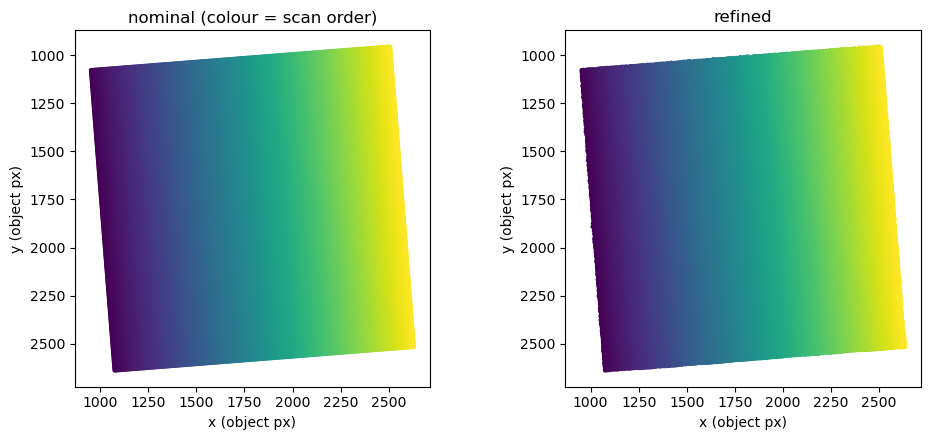

In [6]:
pos = pos_refined if USE_REFINED_POSITIONS else pos_nominal
centre_y, centre_x = (np.array(object_size) - 1) / 2

x_A = (pos[1] - centre_x) * dx_A
y_A = (pos[0] - centre_y) * dx_A
best_positions = np.stack([x_A, y_A]).astype(np.float32)[None]    # (1, 2, K)

shift = np.hypot(*(pos_refined - pos_nominal)) * dx_A
print("best_positions    ", best_positions.shape)
print(f"x range           {x_A.min():.1f} to {x_A.max():.1f} A")
print(f"y range           {y_A.min():.1f} to {y_A.max():.1f} A")
print(f"refined vs nominal: mean {shift.mean():.2f} A, max {shift.max():.2f} A")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].scatter(pos_nominal[1], pos_nominal[0], s=4, c=np.arange(pos.shape[1]))
ax[0].set_title("nominal (colour = scan order)")
ax[1].scatter(pos_refined[1], pos_refined[0], s=4, c=np.arange(pos.shape[1]))
ax[1].set_title("refined")
for a in ax:
    a.set_aspect("equal"); a.invert_yaxis(); a.set_xlabel("x (object px)"); a.set_ylabel("y (object px)")
plt.tight_layout(); plt.show()

## 4. Save the Pelz-format file

In [7]:
with h5py.File(OUTPUT_FILE, "w") as f:
    f["probe"] = probe_out[None]                 # (1, modes, M, M)
    f["best_positions"] = best_positions         # (1, 2, K)
    f.attrs["source"] = os.path.abspath(PTYREX_FILE)
    f.attrs["dx_A"] = dx_A
    f.attrs["energy_eV"] = energy_eV
    f.attrs["refined_positions"] = USE_REFINED_POSITIONS
    f.attrs["centre_obj_px"] = (centre_y, centre_x)

print("wrote", OUTPUT_FILE)
with h5py.File(OUTPUT_FILE, "r") as f:
    for k in f:
        print(f"  {k:16s} {f[k].shape} {f[k].dtype}")

wrote /dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_112119/pty_out/initial_recon/1.h5
  best_positions   (1, 2, 64770) float32
  probe            (1, 5, 240, 240) complex64


## 5. Check it loads the way the Pelz notebook loads it

These are the Pelz notebook's own loading lines, with `select_inds = 0`. If `ZARR_FILE` is set, dx comes from the
zarr metadata exactly as it does there, and the detector size and scan count are checked too.

In [8]:
margin = 5
dx = dx_A
if ZARR_FILE is not None:
    import zarr
    store = zarr.open(ZARR_FILE, mode="r")
    shape = store["/data"].shape
    meta_dict = store["/meta"][0]
    dx = 1 / 2 / meta_dict["k_max"][0]                      # same as the Pelz notebook
    print("zarr data shape   ", shape)
    print("detector size     ", "OK" if shape[-1] == M else f"MISMATCH: zarr {shape[-1]} px, probe window {M} px -> set WINDOW = {shape[-1]}")
    print("scan points       ", "OK" if shape[0] * shape[1] == best_positions.shape[-1] else f"MISMATCH: zarr {shape[0] * shape[1]}, positions {best_positions.shape[-1]}")
    print("pixel size        ", "OK" if abs(dx / dx_A - 1) < 0.01 else f"MISMATCH: zarr k_max gives dx = {dx:.5f}, PtyREX dx = {dx_A:.5f} A")

# smallest scan_shape (even) that keeps every probe window inside the volume
need = 2 * int(np.ceil(max(np.abs(best_positions[0]).max() / dx - margin + 0.5, 0)))
scan_shape = [need, need]

with h5py.File(OUTPUT_FILE, "r") as f:
    probe = f["probe"][0][:, :, :]
    positions = f["best_positions"][0][:, :]
    positions_float = positions / dx + (scan_shape[0] / 2) + margin
    positions_round = np.round(positions_float).astype(np.int64)
    pt = positions_round.T
    pc = np.zeros_like(pt); pc[:, 0] = pt[:, 1]; pc[:, 1] = pt[:, 0]

V_shape1D = scan_shape[0] + M + margin * 2
inside = pc.min() >= 0 and pc.max() <= V_shape1D - M
print("probe             ", probe.shape, "| window check `probe.shape[1] == M1`:", probe.shape[1] == M)
print("positions         ", pc.shape, "min", pc.min(0), "max", pc.max(0), "| inside volume:", inside)

print(f"""
Settings for the Pelz notebook (use the largest scan_shape over all your tilts):
    M1 = {M}
    scan_shape = [{need}, {need}]
    E = {energy_eV:.0f}
    select_inds = {{t: 0 for t in take}}
""")

probe              (5, 240, 240) | window check `probe.shape[1] == M1`: True
positions          (64770, 2) min [3 6] max [1687 1687] | inside volume: True

Settings for the Pelz notebook (use the largest scan_shape over all your tilts):
    M1 = 240
    scan_shape = [1678, 1678]
    E = 300000
    select_inds = {t: 0 for t in take}



## Optional: convert all tilts at once

Fill in `files` with `{tilt number: PtyREX .hdf path}` and run. It uses the settings above.

In [9]:
files = {
    # 171: "/path/to/tilt171_recon.hdf",
    # 173: "/path/to/tilt173_recon.hdf",
}

for tilt, path in files.items():
    with h5py.File(path, "r") as f:
        out = f["entry_1/process_1/output_1"]
        p = out["probe"][()][:, 0, 0, 0, 0]
        p = p if N_MODES is None else p[:N_MODES]
        n = p.shape[-1]; m = n if WINDOW is None else WINDOW; s = n // 2 - m // 2
        p = p[:, s:s + m, s:s + m].astype(np.complex64)
        q = (out["scan_positions"] if USE_REFINED_POSITIONS else f["entry_1/experiment_1/scan/positions"])[()][0]
        c = (np.array(out["object"].shape[-2:]) - 1) / 2
        d = float(np.ravel(f["entry_1/process_1/common_1/dx"][()])[0]) * 1e10
    bp = np.stack([(q[1] - c[1]) * d, (q[0] - c[0]) * d]).astype(np.float32)[None]
    with h5py.File(os.path.join(OUTPUT_FOLDER, f"{tilt}.h5"), "w") as g:
        g["probe"] = p[None]
        g["best_positions"] = bp
        g.attrs["source"] = os.path.abspath(path); g.attrs["dx_A"] = d
    print(f"{tilt}: probe {p.shape}, positions {bp.shape}, max |pos|/dx = {np.abs(bp).max() / d:.1f} px")